In [25]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import qr, qr_insert

from myqr import economic_qr_with_rank_check

import jlinops

# Define $A$

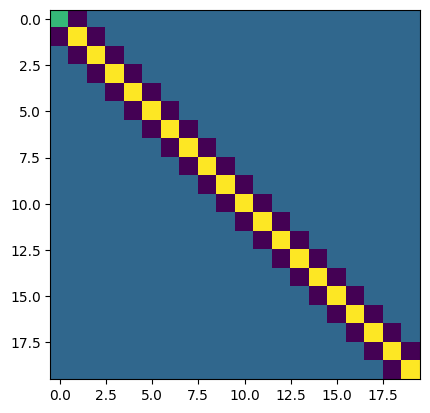

In [2]:
n = 20
A, _ = jlinops.first_order_derivative_1d(n, boundary="zero")
A = A.toarray()
A = A.T @ A
plt.imshow(A)

# Block CG

In [3]:
def block_cg(A, B, X0=None, maxits=None, Xtrue=None):

    # Handle shapes
    k, n = A.shape
    _, m = B.shape

    # Handle initialization
    if X0 is None:
        X = np.zeros((n,m))
    else:
        X = X0

    # Default maxits
    if maxits is None: maxits = int(np.floor(n/m))

    # Startup
    Rprev = (A @ X) - B
    P = -Rprev

    # Tracking
    resid_hist = []
    resid_hist2 = []
    true_err_hist = []
    
    for j in range(maxits):

        # Perform iteration
        AP = A @ P
        PtAP = P.T @ AP
        RprevtRprev = Rprev.T @ Rprev
        L = np.linalg.solve(PtAP, RprevtRprev)
        PL = P @ L
        X = X + PL
        Rnew = Rprev + (A @ PL)
        RnewtRnew = Rnew.T @ Rnew
        Psi = np.linalg.solve(RprevtRprev, RnewtRnew)
        P = -Rnew + P @ Psi

        # Override for next iteration
        RprevtRprev = RnewtRnew
        Rprev = Rnew


        # Compute residual
        resid = np.linalg.norm( (A @ X).flatten() - B.flatten() )
        resid2 = np.linalg.norm(Rnew.flatten())
        resid_hist.append(resid)
        resid_hist2.append(resid2)

        if Xtrue is not None: true_err_hist.append( np.linalg.norm(Xtrue.flatten() - X.flatten()) )

    data = {
        "X": X,
        "resid_hist": np.asarray(resid_hist),
        "resid_hist2": np.asarray(resid_hist2),
        "true_err_hist": np.asarray(true_err_hist),
    }

    return data

# Test it

In [4]:
k, n = A.shape

In [5]:
k, n = A.shape
m = 20
#X_true = 5*np.random.normal(size=(n,m))
X_true = np.arange(n*m).reshape((n,m)) + 5*np.random.normal(size=(n,m))
B = A @ X_true

In [6]:
data = block_cg(A, B, maxits=20, Xtrue=X_true)

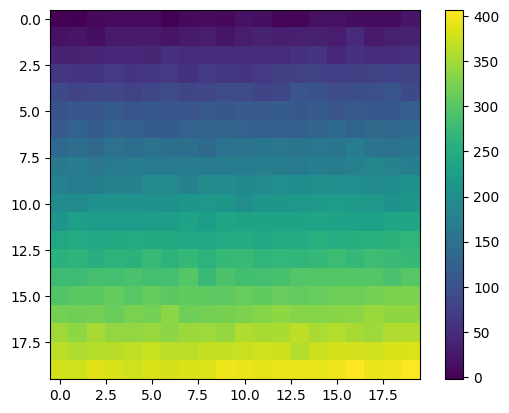

In [7]:
plt.imshow(X_true)
plt.colorbar()
plt.show()

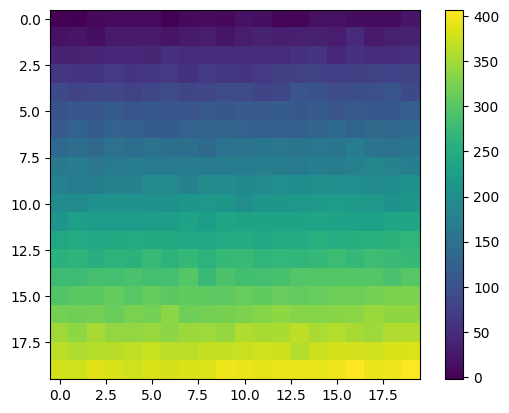

In [8]:
plt.imshow(data["X"])
plt.colorbar()
plt.show()

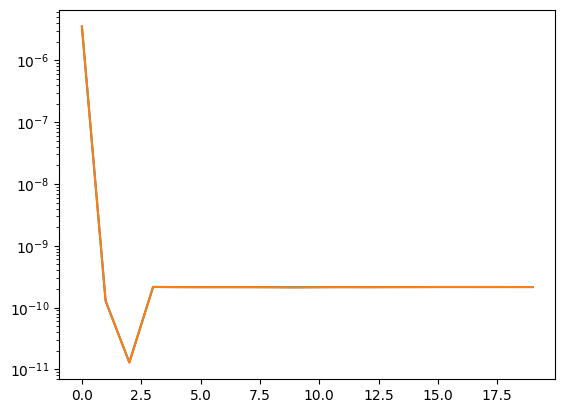

In [9]:
plt.semilogy(data["resid_hist"])
plt.semilogy(data["resid_hist2"])
plt.show()

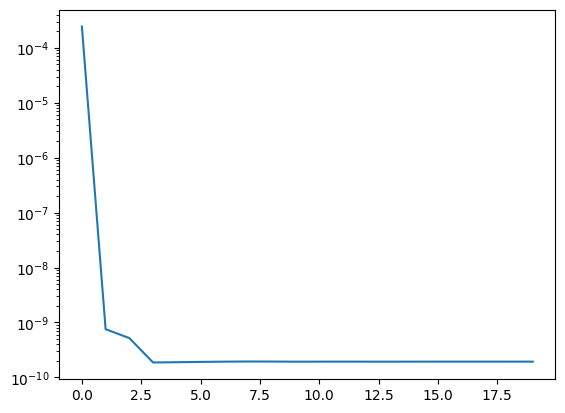

In [10]:
plt.semilogy(data["true_err_hist"])
plt.show()

# Does it still work for singular system?

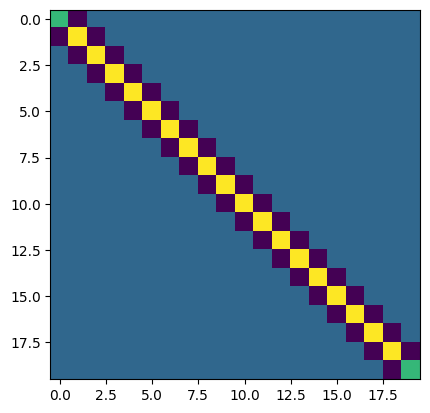

In [11]:
n = 20
A, W = jlinops.first_order_derivative_1d(n, boundary="none")
A = A.toarray()
A = A.T @ A

plt.imshow(A)
plt.show()

In [12]:
k, n = A.shape
m = 20
#X_true = 5*np.random.normal(size=(n,m))
tmp = np.arange(n*m).reshape((n,m)) + 5*np.random.normal(size=(n,m))
X_true = tmp - ( (W @ np.linalg.pinv(W)) @ tmp )
B = A @ X_true

In [13]:
data = block_cg(A, B, maxits=10, Xtrue=X_true)

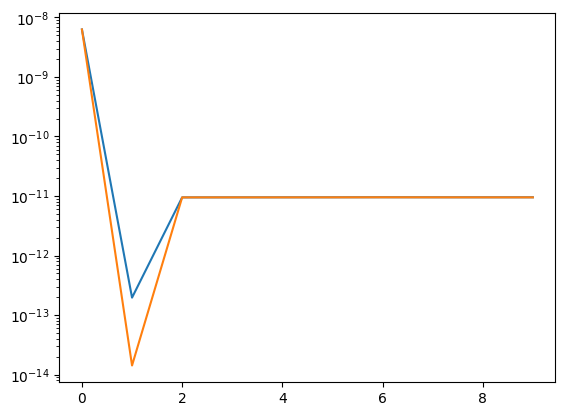

In [14]:
plt.semilogy(data["resid_hist"])
plt.semilogy(data["resid_hist2"])
plt.show()

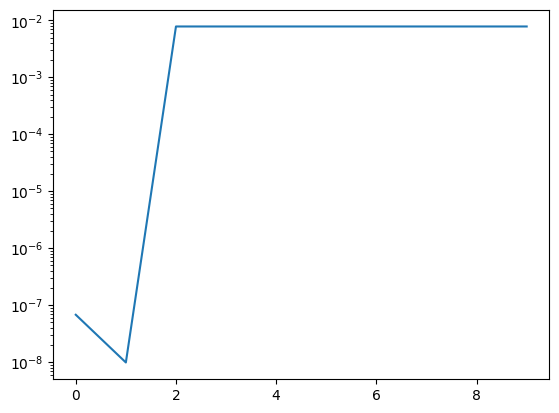

In [15]:
plt.semilogy(data["true_err_hist"])
plt.show()

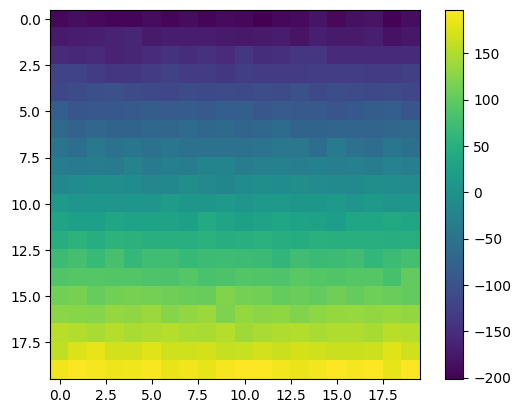

In [16]:
plt.imshow(X_true)
plt.colorbar()
plt.show()

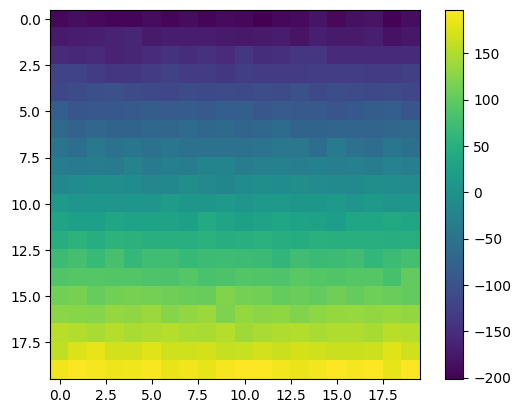

In [17]:
plt.imshow(data["X"])
plt.colorbar()
plt.show()

# Unequal convergence version

In [26]:
def block_cg(A, B, X0=None, maxits=None, Xtrue=None):

    # Handle shapes
    k, n = A.shape
    _, m = B.shape

    # Handle initialization
    if X0 is None:
        X = np.zeros((n,m))
        X0 = np.zeros((n,m))
    else:
        X = X0

    # Default maxits
    if maxits is None: maxits = int(np.floor(n/m))

    # QR factor initial R0
    Rinit = (A @ X - B)
    Qfac, Rfac, _ = economic_qr_with_rank_check(Rinit)
    #rank = qr_fac.Q.shape[1]

    # Startup
    Rprev = Qfac
    P = -Rprev
    X = np.zeros((n,m))

    # Tracking
    resid_hist = []
    resid_hist2 = []
    true_err_hist = []
    
    for j in range(maxits):

        print(j)
        
        # Perform iteration
        AP = A @ P
        PtAP = P.T @ AP
        RprevtRprev = Rprev.T @ Rprev
        L = np.linalg.solve(PtAP, RprevtRprev)
        PL = P @ L
        X = X + PL
        Rnew = Rprev + (A @ PL)
        RnewtRnew = Rnew.T @ Rnew
        Psi = np.linalg.solve(RprevtRprev, RnewtRnew)
        P = -Rnew + P @ Psi

        # Override for next iteration
        RprevtRprev = RnewtRnew
        Rprev = Rnew

        # Compute residual
        resid = np.linalg.norm( (A @ (X0 + (X @ Rfac) ) ).flatten() - B.flatten() )
        resid2 = np.linalg.norm(Rnew.flatten())
        resid_hist.append(resid)
        resid_hist2.append(resid2)

        if Xtrue is not None: true_err_hist.append( np.linalg.norm(Xtrue.flatten() - (X0 + (X @ Rfac)).flatten()) )

    X = X0 + (X @ Rfac)

    data = {
        "X": X,
        "resid_hist": np.asarray(resid_hist),
        "resid_hist2": np.asarray(resid_hist2),
        "true_err_hist": np.asarray(true_err_hist),
    }

    return data

In [27]:
n = 20
A, _ = jlinops.first_order_derivative_1d(n, boundary="none")
A = A.toarray()
A = A.T @ A
# plt.imshow(A)

k, n = A.shape
m = 5
#X_true = 5*np.random.normal(size=(n,m))
tmp = np.arange(n*m).reshape((n,m)) + 5*np.random.normal(size=(n,m))
X_true = tmp - ( (W @ np.linalg.pinv(W)) @ tmp )
#X_true = np.ones((n,m))
B = A @ X_true

In [28]:
n/m

4.0

In [29]:
data = block_cg(A, B, maxits=5, Xtrue=X_true)

Rank of R: 5
0
1
2
3
4


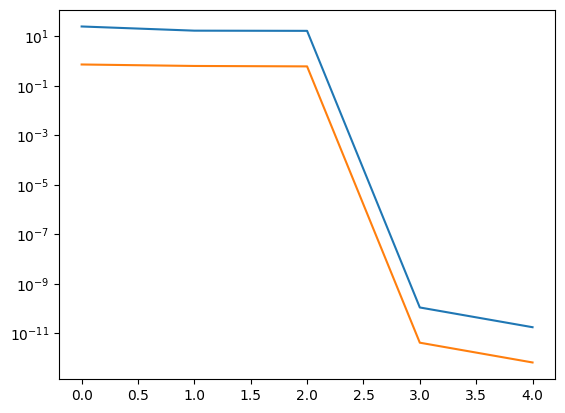

In [30]:
plt.semilogy(data["resid_hist"])
plt.semilogy(data["resid_hist2"])
plt.show()

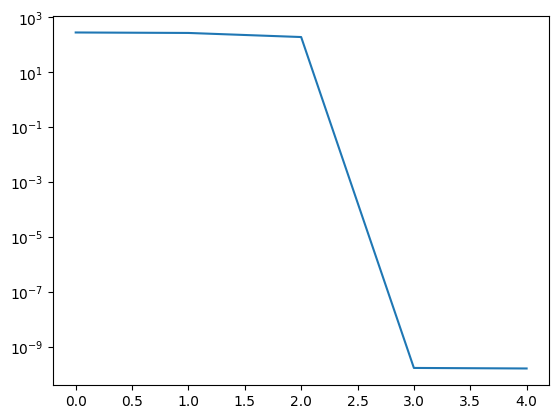

In [31]:
plt.semilogy(data["true_err_hist"])
plt.show()

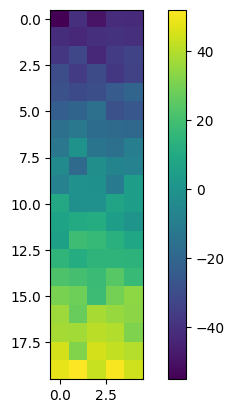

In [32]:
plt.imshow(X_true)
plt.colorbar()
plt.show()

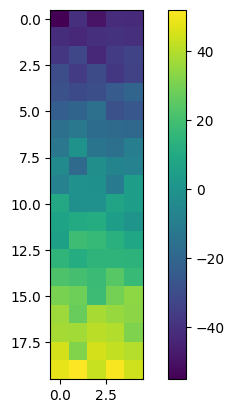

In [33]:
plt.imshow(data["X"])
plt.colorbar()
plt.show()

# Final version with internal deflation

In [34]:
def block_cg(A, B, X0=None, maxits=None, Xtrue=None):

    # Handle shapes
    k, n = A.shape
    _, m = B.shape

    # Handle initialization
    if X0 is None:
        X = np.zeros((n,m))
        X0 = np.zeros((n,m))
    else:
        X = X0

    # Default maxits
    if maxits is None: maxits = int(np.floor(n/m))

    # QR factor initial R0
    Rinit = (A @ X - B)
    Qfac, Rfac, rank_Rinit = economic_qr_with_rank_check(Rinit)
    #rank = qr_fac.Q.shape[1]
    
    # Startup
    Rprev = Qfac
    P = -Rprev
    X = np.zeros((n,m))

    # Tracking
    resid_hist = []
    resid_hist2 = []
    true_err_hist = []
    
    
    for j in range(maxits):

        print(j)

        # Check that P has full rank
        Qfac_P, Rfac_P, rank_P = economic_qr_with_rank_check(P)
        if rank_P == P.shape[1]:
            pass
        else:
            print("P no longer has full rank.")

        # Check that R has full rank
        Qfac_Rprev, Rfac_Rprev, rank_Rprev = economic_qr_with_rank_check(Rprev)
        if rank_Rprev == Rprev.shape[1]:
            pass
        else:
            print("Rprev no longer has full rank.")

        # Check that X has full rank
        Qfac_X, Rfac_X, rank_X = economic_qr_with_rank_check(X)
        if rank_X == X.shape[1]:
            pass
        else:
            print("X no longer has full rank.")

        # Perform iteration
        AP = A @ P
        PtAP = P.T @ AP
        RprevtRprev = Rprev.T @ Rprev
        L = np.linalg.solve(PtAP, RprevtRprev)
        PL = P @ L
        X = X + PL
        Rnew = Rprev + (A @ PL)
        RnewtRnew = Rnew.T @ Rnew
        Psi = np.linalg.solve(RprevtRprev, RnewtRnew)
        P = -Rnew + P @ Psi

        # Override for next iteration
        RprevtRprev = RnewtRnew
        Rprev = Rnew

        # Compute residual
        resid = np.linalg.norm( (A @ (X0 + (X @ Rfac) ) ).flatten() - B.flatten() )
        resid2 = np.linalg.norm(Rnew.flatten())
        resid_hist.append(resid)
        resid_hist2.append(resid2)

        if Xtrue is not None: true_err_hist.append( np.linalg.norm(Xtrue.flatten() - (X0 + (X @ Rfac)).flatten()) )

    X = X0 + (X @ Rfac)

    data = {
        "X": X,
        "resid_hist": np.asarray(resid_hist),
        "resid_hist2": np.asarray(resid_hist2),
        "true_err_hist": np.asarray(true_err_hist),
    }

    return data

In [57]:
n = 20
A, _ = jlinops.first_order_derivative_1d(n, boundary="zero")
A = A.toarray()
A = A.T @ A
# plt.imshow(A)

k, n = A.shape
m = 5
#X_true = 5*np.random.normal(size=(n,m))

np.random.seed(0)
X_true = np.arange(n*m).reshape((n,m)) + 5*np.random.normal(size=(n,m))

#tmp = np.arange(n*m).reshape((n,m)) + 5*np.random.normal(size=(n,m))
#X_true = tmp - ( (W @ np.linalg.pinv(W)) @ tmp )

#X_true = np.ones((n,m))

B = A @ X_true

In [59]:
data = block_cg(A, B, maxits=25, Xtrue=X_true)

Rank of R: 5
0
Rank of R: 5
Rank of R: 5
Rank of R: 0
X no longer has full rank.
1
Rank of R: 5
Rank of R: 5
Rank of R: 5
2
Rank of R: 5
Rank of R: 5
Rank of R: 5
3
Rank of R: 5
Rank of R: 5
Rank of R: 5
4
Rank of R: 5
Rank of R: 5
Rank of R: 5
5
Rank of R: 5
Rank of R: 5
Rank of R: 5
6
Rank of R: 5
Rank of R: 5
Rank of R: 5
7
Rank of R: 5
Rank of R: 5
Rank of R: 5
8
Rank of R: 5
Rank of R: 5
Rank of R: 5
9
Rank of R: 5
Rank of R: 5
Rank of R: 5
10
Rank of R: 5
Rank of R: 5
Rank of R: 5
11
Rank of R: 5
Rank of R: 5
Rank of R: 5
12
Rank of R: 5
Rank of R: 5
Rank of R: 5
13
Rank of R: 5
Rank of R: 5
Rank of R: 5
14
Rank of R: 5
Rank of R: 5
Rank of R: 5
15
Rank of R: 5
Rank of R: 5
Rank of R: 5
16
Rank of R: 5
Rank of R: 5
Rank of R: 5
17
Rank of R: 5
Rank of R: 5
Rank of R: 5
18
Rank of R: 5
Rank of R: 5
Rank of R: 5
19
Rank of R: 5
Rank of R: 5
Rank of R: 5
20
Rank of R: 5
Rank of R: 5
Rank of R: 5
21
Rank of R: 5
Rank of R: 5
Rank of R: 5
22
Rank of R: 5
Rank of R: 5
Rank of R: 5
23
R

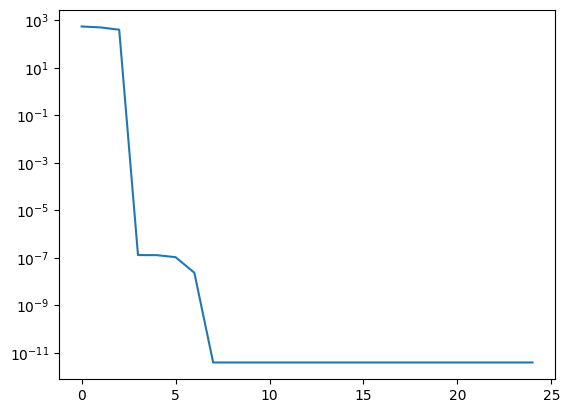

In [60]:
plt.semilogy(data["true_err_hist"])
plt.show()

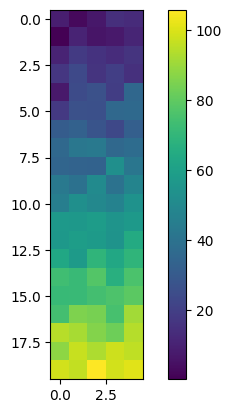

In [61]:
plt.imshow(X_true)
plt.colorbar()
plt.show()

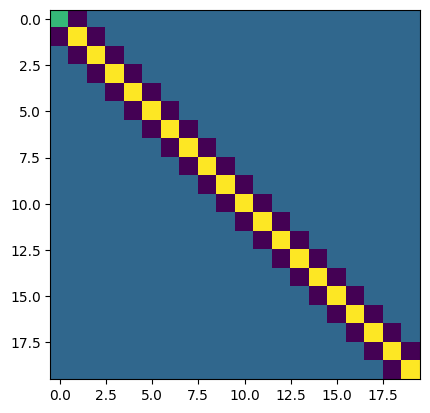

In [62]:
plt.imshow(A)
plt.show()

# Just use lobcg

In [24]:
from scipy.sparse.linalg import lobpcg